# Лабораторная работа №15: Flow matching и rectified flow

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать 2D rectified flow.
- Визуализировать vector field и trajectories.
- Сравнить Euler steps и diffusion baseline.

## Теоретическая часть

Flow matching обучает vector field $v_\theta(x_t,t)$, переносящий простое распределение в data distribution. Для rectified path $x_t=(1-t)x_0+tx_1$ target velocity равна $x_1-x_0$. Sampling решает ODE.

![Flow matching paths](https://raw.githubusercontent.com/atong01/conditional-flow-matching/main/assets/cfm.png)


Rectified flow строит линейный путь x_t=(1−t)x₀+tx₁ с полем v*=x₁−x₀; интегрирование ODE Euler переносит шум к данным. На двумерном распределении можно оценить покрытие мод и нарисовать траектории; VP diffusion служит отдельно обучаемой контрольной моделью при том же бюджете.

Для VP-пути $x_t=\cos(\pi t/2)x_1+\sin(\pi t/2)\epsilon$. В предельной точке $t=1$ восстановление $x_1$ через деление на $\alpha_t$ не определено: в коде используется явно ограниченное $t\leq0.9$ как приближение шумового старта.

### Экспериментальный протокол

Демонстрационная задача — восьмимодальное 2D распределение, а не MNIST. Полный режим обучает две отдельные модели по 3000 шагов и coupling ablation; smoke — 3 шага, его картинки/метрики не используются в выводах. Все числовые метрики рассчитываются из фактических точек относительно test.

### Материалы

- [Conditional Flow Matching](https://github.com/atong01/conditional-flow-matching)
- [Flow Matching paper](https://arxiv.org/abs/2210.02747)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [13]:
# Настройки Colab: весь эксперимент воспроизводим и пишет файлы только в ./artifacts.
from pathlib import Path
import os, json, random, time, math, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from IPython.display import display

SEED = 42
FAST_DEV_RUN = False  # Сначала smoke (3 шага), после проверки переключить на False (3000 шагов).
RUN_TAG = 'smoke' if FAST_DEV_RUN else 'full'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path.cwd() / 'artifacts'
ARTIFACTS.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

def artifact(name):
    return ARTIFACTS / f'{RUN_TAG}_{name}'

def save_json(name, obj):
    artifact(name).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')

save_json('environment.json', {'python': platform.python_version(), 'torch': torch.__version__,
    'cuda': torch.version.cuda, 'numpy': np.__version__, 'pandas': pd.__version__,
    'matplotlib': plt.matplotlib.__version__, 'seaborn': sns.__version__,
    'device': DEVICE, 'seed': SEED, 'fast_dev_run': FAST_DEV_RUN})
print(f'Device: {DEVICE} | FAST_DEV_RUN: {FAST_DEV_RUN} | artifacts: {ARTIFACTS}')
print(f'PyTorch: {torch.__version__} | NumPy: {np.__version__} | pandas: {pd.__version__}')
if DEVICE != 'cuda':
    print('Внимание: для полного обучения включите GPU: Runtime → Change runtime type → T4 GPU.')


Device: cuda | FAST_DEV_RUN: False | artifacts: /content/artifacts
PyTorch: 2.14.1+cu130 | NumPy: 2.4.6 | pandas: 2.2.3


### Геометрия восьмимодального распределения

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте независимые train/test выборки с фиксированными seed и центрами мод.

**Результат.** Проверяемое состояние «Геометрия восьмимодального распределения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте независимые train/test выборки с фиксированными seed и центрами мод» и его результат доступен следующему этапу.

,мода,train,test,центр_x,центр_y
0,0,4096,1024,2.000,0.000
1,1,4096,1024,1.414,1.414
2,2,4096,1024,0.000,2.000
3,3,4096,1024,-1.414,1.414
4,4,4096,1024,-2.000,0.000
5,5,4096,1024,-1.414,-1.414
6,6,4096,1024,-0.000,-2.000
7,7,4096,1024,1.414,-1.414


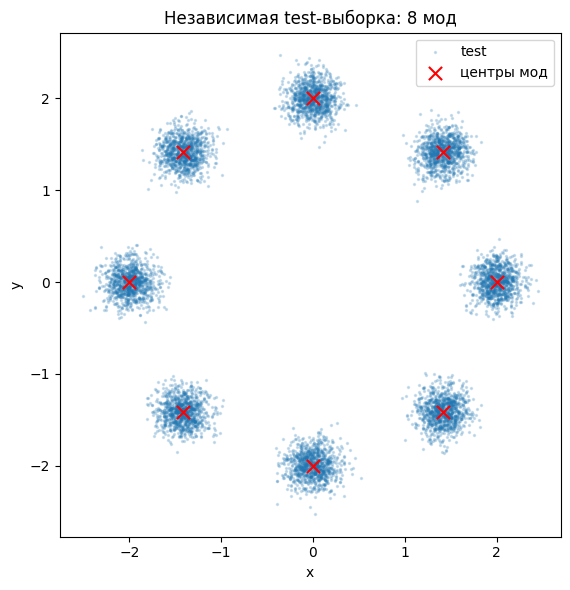

In [14]:
# Независимые seed и одинаковые центры дают честный train/test без утечки точек.
N_TRAIN, N_TEST = 32768, 8192
N_MODES, RADIUS, MODE_STD = 8, 2.0, 0.14
angles = 2 * np.pi * np.arange(N_MODES) / N_MODES
centers = np.stack([RADIUS * np.cos(angles), RADIUS * np.sin(angles)], axis=1).astype('float32')

def make_modes(n, seed):
    rng = np.random.default_rng(seed)
    labels = np.arange(n, dtype=np.int64) % N_MODES
    rng.shuffle(labels)
    points = centers[labels] + rng.normal(0, MODE_STD, size=(n, 2)).astype('float32')
    return torch.from_numpy(points), torch.from_numpy(labels)

train_cpu, train_labels = make_modes(N_TRAIN, SEED + 11)
test_cpu, test_labels = make_modes(N_TEST, SEED + 29)
train_points = train_cpu.to(DEVICE)
test_np = test_cpu.numpy()

counts = pd.DataFrame({
    'мода': np.arange(N_MODES),
    'train': torch.bincount(train_labels, minlength=N_MODES).numpy(),
    'test': torch.bincount(test_labels, minlength=N_MODES).numpy(),
    'центр_x': centers[:, 0].round(3), 'центр_y': centers[:, 1].round(3)
})
display(counts)
torch.save({'train': train_cpu, 'test': test_cpu, 'centers': torch.from_numpy(centers),
            'train_labels': train_labels, 'test_labels': test_labels}, artifact('dataset.pt'))
save_json('data_info.json', {'source': 'Самостоятельно сгенерированная смесь 8 двумерных Gaussian',
    'license': 'Внешние данные и предобученные веса не используются', 'seed_train': SEED + 11,
    'seed_test': SEED + 29, 'n_train': N_TRAIN, 'n_test': N_TEST,
    'radius': RADIUS, 'std': MODE_STD, 'centers': centers.tolist()})

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test_np[:, 0], test_np[:, 1], s=2, alpha=0.2, label='test')
ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='x', s=90, label='центры мод')
ax.set(aspect='equal', title='Независимая test-выборка: 8 мод', xlabel='x', ylabel='y')
ax.legend()
fig.tight_layout(); fig.savefig(artifact('test_modes.png'), dpi=160); plt.show()


### Векторное поле и линейный путь

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите MLP и визуализируйте линейный путь между шумом и реальными точками.

**Результат.** Проверяемое состояние «Векторное поле и линейный путь» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите MLP и визуализируйте линейный путь между шумом и реальными точками» и его результат доступен следующему этапу.

Flow MLP, параметров: 34306


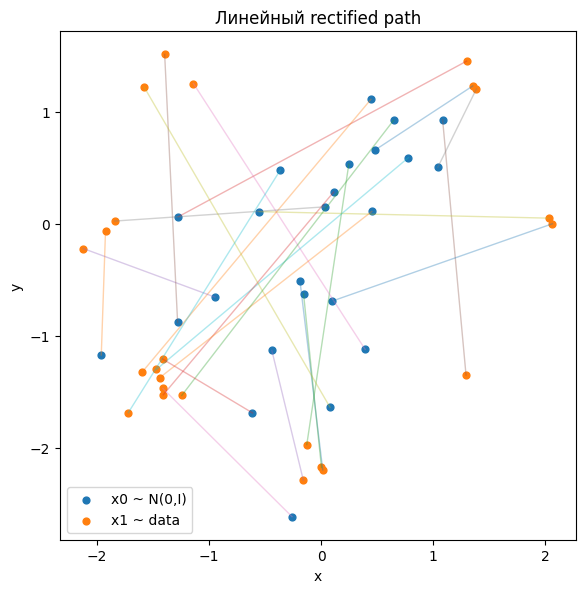

In [15]:
# MLP получает координаты и периодические признаки времени; это поле dx/dt = v(x,t).
class TimeMLP(nn.Module):
    def __init__(self, width=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(7, width), nn.SiLU(),
            nn.Linear(width, width), nn.SiLU(),
            nn.Linear(width, width), nn.SiLU(),
            nn.Linear(width, 2)
        )

    def forward(self, x, t):
        t = t.reshape(-1, 1)
        features = torch.cat([x, t, torch.sin(2 * math.pi * t),
            torch.cos(2 * math.pi * t), torch.sin(4 * math.pi * t),
            torch.cos(4 * math.pi * t)], dim=1)
        return self.net(features)

set_seed(SEED)  # Та же инициализация будет у VP и angular flow.
flow_model = TimeMLP().to(DEVICE)
print('Flow MLP, параметров:', sum(p.numel() for p in flow_model.parameters()))

# Прямые x_t=(1-t)x0+t*x1 визуализируют обучающие пути до обучения поля.
g = torch.Generator(device='cpu').manual_seed(SEED + 71)
x0_vis = torch.randn(24, 2, generator=g).numpy()
x1_vis = train_cpu[:24].numpy()
fig, ax = plt.subplots(figsize=(6, 6))
for a, b in zip(x0_vis, x1_vis):
    line = (1 - np.linspace(0, 1, 30)[:, None]) * a + np.linspace(0, 1, 30)[:, None] * b
    ax.plot(line[:, 0], line[:, 1], alpha=0.35, lw=1)
ax.scatter(x0_vis[:, 0], x0_vis[:, 1], s=24, label='x0 ~ N(0,I)')
ax.scatter(x1_vis[:, 0], x1_vis[:, 1], s=24, label='x1 ~ data')
ax.set(xlabel='x', ylabel='y', title='Линейный rectified path', aspect='equal')
ax.legend(); fig.tight_layout()
fig.savefig(artifact('linear_paths.png'), dpi=160); plt.show()


### Вторая модель для VP diffusion

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную модель и два независимых оптимизатора.

**Результат.** Проверяемое состояние «Вторая модель для VP diffusion» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную модель и два независимых оптимизатора» и его результат доступен следующему этапу.

In [16]:
# Diffusion учим отдельно прогнозировать шум ε, а не скорость flow.
set_seed(SEED)  # Равные стартовые веса исключают шум инициализации из сравнения.
vp_model = TimeMLP().to(DEVICE)
LR, WEIGHT_DECAY = 1e-3, 1e-4
BATCH_SIZE = 128 if FAST_DEV_RUN else 512
TRAIN_STEPS = 3 if FAST_DEV_RUN else 3000
VP_T_MAX = 0.9  # α(t)>0: нет деления на нуль при обратном шаге.
flow_optimizer = torch.optim.AdamW(flow_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
vp_optimizer = torch.optim.AdamW(vp_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def vp_alpha_sigma(t):
    return torch.cos(math.pi * t / 2), torch.sin(math.pi * t / 2)

assert flow_model is not vp_model and flow_optimizer is not vp_optimizer
print(pd.DataFrame([
    {'модель': 'Rectified flow', 'оптимизатор': 'AdamW', 'шагов': TRAIN_STEPS, 'batch': BATCH_SIZE},
    {'модель': 'VP diffusion ε-pred', 'оптимизатор': 'AdamW', 'шагов': TRAIN_STEPS, 'batch': BATCH_SIZE}
]).to_string(index=False))


             модель оптимизатор  шагов  batch
     Rectified flow       AdamW   3000    512
VP diffusion ε-pred       AdamW   3000    512


### Обучение при равном бюджете

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери.

**Результат.** Проверяемое состояние «Обучение при равном бюджете» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери» и его результат доступен следующему этапу.

In [17]:
# Одинаковые x1, шум, время и число optimizer.step(); loss разных задач напрямую не сравниваем.
train_config = {'seed': SEED, 'train_steps': TRAIN_STEPS, 'batch_size': BATCH_SIZE,
                'lr': LR, 'weight_decay': WEIGHT_DECAY, 'vp_t_max': VP_T_MAX}
checkpoint_path = artifact('joint_checkpoint.pt')
train_rng = torch.Generator(device=DEVICE).manual_seed(SEED + 100)
history = {'step': [], 'flow_loss': [], 'vp_loss': []}
start_step, accumulated_seconds = 0, 0.0
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    if checkpoint.get('config') == train_config:
        flow_model.load_state_dict(checkpoint['flow_model'])
        vp_model.load_state_dict(checkpoint['vp_model'])
        flow_optimizer.load_state_dict(checkpoint['flow_optimizer'])
        vp_optimizer.load_state_dict(checkpoint['vp_optimizer'])
        train_rng.set_state(checkpoint['rng_state'])
        history = checkpoint['history']
        start_step = checkpoint['step']
        accumulated_seconds = checkpoint.get('train_seconds', 0.0)
        print(f'Возобновление совместного обучения с шага {start_step}/{TRAIN_STEPS}')

def save_joint(step, elapsed):
    torch.save({'config': train_config, 'step': step,
        'flow_model': flow_model.state_dict(), 'vp_model': vp_model.state_dict(),
        'flow_optimizer': flow_optimizer.state_dict(), 'vp_optimizer': vp_optimizer.state_dict(),
        'rng_state': train_rng.get_state(), 'history': history,
        'train_seconds': elapsed}, checkpoint_path)

flow_model.train(); vp_model.train()
timer = time.perf_counter()
for step in range(start_step + 1, TRAIN_STEPS + 1):
    idx = torch.randint(N_TRAIN, (BATCH_SIZE,), generator=train_rng, device=DEVICE)
    x1 = train_points[idx]
    eps = torch.randn(BATCH_SIZE, 2, generator=train_rng, device=DEVICE)
    t_raw = torch.rand(BATCH_SIZE, 1, generator=train_rng, device=DEVICE)

    xt_flow = (1 - t_raw) * eps + t_raw * x1
    flow_loss = (flow_model(xt_flow, t_raw) - (x1 - eps)).square().mean()
    flow_optimizer.zero_grad(set_to_none=True)
    flow_loss.backward()
    flow_optimizer.step()

    t_vp = VP_T_MAX * t_raw
    alpha, sigma = vp_alpha_sigma(t_vp)
    xt_vp = alpha * x1 + sigma * eps
    vp_loss = (vp_model(xt_vp, t_vp) - eps).square().mean()
    vp_optimizer.zero_grad(set_to_none=True)
    vp_loss.backward()
    vp_optimizer.step()

    history['step'].append(step)
    history['flow_loss'].append(float(flow_loss.detach()))
    history['vp_loss'].append(float(vp_loss.detach()))
    if step == TRAIN_STEPS or step % (1 if FAST_DEV_RUN else 500) == 0:
        elapsed = accumulated_seconds + time.perf_counter() - timer
        save_joint(step, elapsed)
        print(f'{step:4d}/{TRAIN_STEPS}: flow={history["flow_loss"][-1]:.4f}, '
              f'VP={history["vp_loss"][-1]:.4f}, time={elapsed:.1f}s')

train_seconds = accumulated_seconds + time.perf_counter() - timer
assert len(history['step']) == TRAIN_STEPS
print('Обновлений каждой модели:', TRAIN_STEPS, '| Время совместного обучения:', round(train_seconds, 2), 'с')


 500/3000: flow=1.8995, VP=0.4868, time=2.0s
1000/3000: flow=2.0842, VP=0.5592, time=4.0s
1500/3000: flow=1.9375, VP=0.4851, time=5.9s
2000/3000: flow=1.9345, VP=0.4912, time=8.2s
2500/3000: flow=1.7185, VP=0.4292, time=10.8s
3000/3000: flow=1.8107, VP=0.4441, time=12.7s
Обновлений каждой модели: 3000 | Время совместного обучения: 12.75 с


### Фиксация траекторий обучения

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните историю, доступную после возобновления checkpoint.

**Результат.** Проверяемое состояние «Фиксация траекторий обучения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните историю, доступную после возобновления checkpoint» и его результат доступен следующему этапу.

,step,flow_loss,vp_loss
2990,2991,2.026786,0.472676
2991,2992,1.960630,0.468511
2992,2993,1.882053,0.456876
2993,2994,1.884408,0.519755
2994,2995,1.954357,0.466212
2995,2996,1.759730,0.398127
2996,2997,1.868375,0.445104
2997,2998,1.814078,0.433351
2998,2999,1.942672,0.485133
2999,3000,1.810665,0.444129


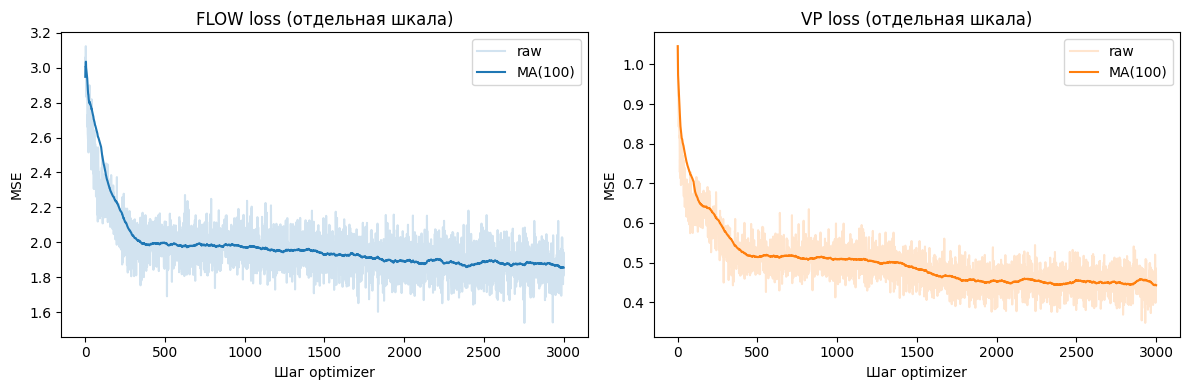

Checkpoint с весами, optimizer, RNG и историей: /content/artifacts/full_joint_checkpoint.pt


In [18]:
# История и состояние optimizer внутри checkpoint обеспечивают корректный resume.
loss_df = pd.DataFrame(history)
loss_df['flow_ma'] = loss_df['flow_loss'].rolling(100, min_periods=1).mean()
loss_df['vp_ma'] = loss_df['vp_loss'].rolling(100, min_periods=1).mean()
display(loss_df[['step', 'flow_loss', 'vp_loss']].tail(10))
save_json('train_history.json', {'config': train_config, 'steps': history['step'],
    'flow_loss': history['flow_loss'], 'vp_loss': history['vp_loss'],
    'joint_train_seconds': round(train_seconds, 3)})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, color in [(axes[0], 'flow', 'tab:blue'), (axes[1], 'vp', 'tab:orange')]:
    ax.plot(loss_df['step'], loss_df[f'{name}_loss'], color=color, alpha=0.2, label='raw')
    ax.plot(loss_df['step'], loss_df[f'{name}_ma'], color=color, label='MA(100)')
    ax.set(xlabel='Шаг optimizer', ylabel='MSE', title=f'{name.upper()} loss (отдельная шкала)')
    ax.legend()
fig.tight_layout(); fig.savefig(artifact('learning_curves.png'), dpi=160); plt.show()
print('Checkpoint с весами, optimizer, RNG и историей:', checkpoint_path)


### Интеграторы и начальное распределение

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум.

**Результат.** Проверяемое состояние «Интеграторы и начальное распределение» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум» и его результат доступен следующему этапу.

In [19]:
# Оба sampler получают одну и ту же исходную гауссовскую выборку.
EVAL_N = 256 if FAST_DEV_RUN else 4096
EULER_STEPS = [4, 16] if FAST_DEV_RUN else [4, 8, 16, 32, 64]
noise_rng = torch.Generator(device=DEVICE).manual_seed(SEED + 202)
initial_noise = torch.randn(EVAL_N, 2, generator=noise_rng, device=DEVICE)

@torch.inference_mode()
def sample_flow(model, z, steps, track=0):
    model.eval()
    x = z.clone()
    trajectories = [x[:track].detach().cpu().numpy()] if track else []
    for k in range(steps):
        t = torch.full((len(x), 1), k / steps, device=x.device, dtype=x.dtype)
        x = x + model(x, t) / steps
        if track:
            trajectories.append(x[:track].detach().cpu().numpy())
    return x, np.stack(trajectories) if track else None

@torch.inference_mode()
def sample_vp(model, z, steps):
    model.eval()
    x = z.clone()
    for k in range(steps):
        t = VP_T_MAX * (1 - k / steps)
        t_next = VP_T_MAX * (1 - (k + 1) / steps)
        a, s = math.cos(math.pi*t/2), math.sin(math.pi*t/2)
        a_next, s_next = math.cos(math.pi*t_next/2), math.sin(math.pi*t_next/2)
        model_t = torch.full((len(x), 1), t, device=x.device, dtype=x.dtype)
        predicted_eps = model(x, model_t)
        predicted_data = (x - s * predicted_eps) / a  # a>=cos(0.9π/2)>0.
        x = a_next * predicted_data + s_next * predicted_eps
    return x

flow_check, _ = sample_flow(flow_model, initial_noise, 4)
vp_check = sample_vp(vp_model, initial_noise, 4)
assert torch.isfinite(flow_check).all() and torch.isfinite(vp_check).all()
save_json('integrators.json', {'flow': 'explicit Euler, forward t:0→1',
    'vp': 'deterministic DDIM-like update, backward t:0.9→0',
    'vp_t_max': VP_T_MAX, 'n_initial_samples': EVAL_N, 'steps_checked': EULER_STEPS})
print('Проверка интеграторов: все значения конечные.', 'α(0.9)=', round(math.cos(math.pi*.9/2), 4))


Проверка интеграторов: все значения конечные. α(0.9)= 0.1564


### Оценка покрытия мод на test

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте качество каждого sampler по независимому test и сохраните изображения.

**Результат.** Проверяемое состояние «Оценка покрытия мод на test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте качество каждого sampler по независимому test и сохраните изображения» и его результат доступен следующему этапу.

,model,steps,nfe,sample_seconds,mmd2,coverage_8,inlier_rate,mode_tv,mean_mode_distance
0,flow,4,4,0.00173,0.00558,8,0.78589,0.03662,0.23364
1,flow,8,8,0.00334,0.00379,8,0.88037,0.03149,0.19704
2,flow,16,16,0.00644,0.00330,8,0.91968,0.03101,0.18696
3,flow,32,32,0.01204,0.00336,8,0.93481,0.02979,0.18316
4,flow,64,64,0.02365,0.00344,8,0.94067,0.02856,0.18146
5,vp,4,4,0.00203,0.00547,8,0.82568,0.06885,0.20746
6,vp,8,8,0.00411,0.00320,8,0.88916,0.03784,0.19075
7,vp,16,16,0.00722,0.00260,8,0.92017,0.02930,0.18723
8,vp,32,32,0.01383,0.00248,8,0.93506,0.02417,0.18575
9,vp,64,64,0.02650,0.00245,8,0.93970,0.02417,0.18510


Test threshold (99% радиуса): 0.4289 | test-vs-test MMD²: 0.00134


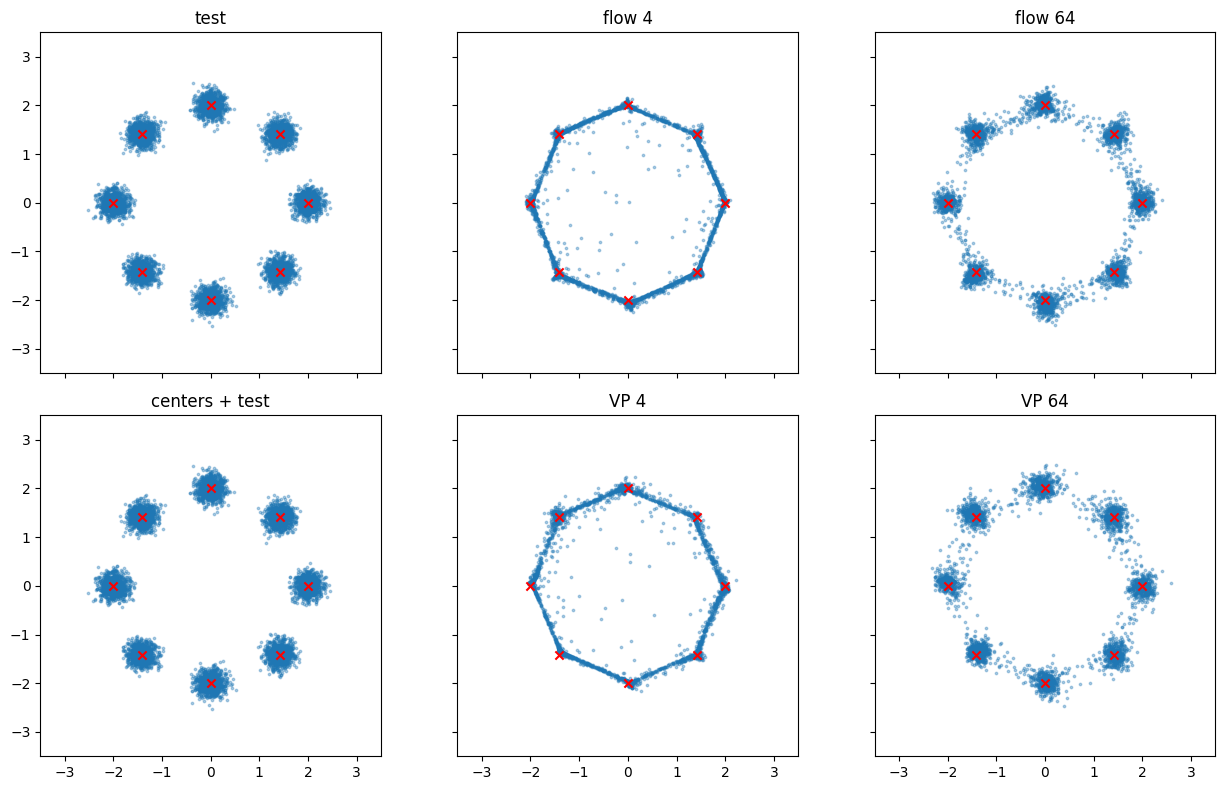

In [20]:
# Сравниваем с независимым test по MMD², близости к модам и распределению масс.
test_dist = np.min(np.linalg.norm(test_np[:, None, :] - centers[None, :, :], axis=2), axis=1)
inlier_threshold = float(np.quantile(test_dist, 0.99))
test_assign = np.argmin(np.linalg.norm(test_np[:, None, :] - centers[None, :, :], axis=2), axis=1)
test_probs = np.bincount(test_assign, minlength=N_MODES) / len(test_assign)
ref_rng = np.random.default_rng(SEED + 303)
ref_ids = ref_rng.permutation(len(test_np))
mmd_ref = test_np[ref_ids[:512]].astype(np.float64)
mmd_test_second = test_np[ref_ids[512:1024]].astype(np.float64)

def rbf_mmd2(a, b):
    # Фиксированная multi-scale RBF MMD² с неотрицательной biased-оценкой.
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    def distances(u, v):
        return np.maximum((u*u).sum(1)[:, None] + (v*v).sum(1)[None, :] - 2*u@v.T, 0)
    aa, bb, ab = distances(a, a), distances(b, b), distances(a, b)
    return float(max(0, np.mean([
        np.exp(-aa/(2*s*s)).mean() + np.exp(-bb/(2*s*s)).mean()
        - 2*np.exp(-ab/(2*s*s)).mean() for s in (0.2, 0.5, 1., 2.)
    ])))

def evaluate_samples(points):
    p = np.asarray(points, dtype=np.float32)
    distances = np.linalg.norm(p[:, None, :] - centers[None, :, :], axis=2)
    labels = distances.argmin(axis=1)
    radii = distances.min(axis=1)
    counts = np.bincount(labels[radii <= inlier_threshold], minlength=N_MODES)
    probs = np.bincount(labels, minlength=N_MODES) / len(p)
    return {'mmd2': rbf_mmd2(p[:min(512, len(p))], mmd_ref),
            'coverage_8': int((counts >= max(1, 0.01*len(p))).sum()),
            'inlier_rate': float((radii <= inlier_threshold).mean()),
            'mode_tv': float(0.5 * np.abs(probs - test_probs).sum()),
            'mean_mode_distance': float(radii.mean())}

def synchronize():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()

sampler_rows, samples = [], {}
for method in ('flow', 'vp'):
    for n_steps in EULER_STEPS:
        synchronize(); tic = time.perf_counter()
        pts = (sample_flow(flow_model, initial_noise, n_steps)[0] if method == 'flow'
               else sample_vp(vp_model, initial_noise, n_steps))
        synchronize(); seconds = time.perf_counter() - tic
        np_pts = pts.cpu().numpy()
        name = f'{method}_{n_steps}'
        samples[name] = np_pts
        sampler_rows.append({'model': method, 'steps': n_steps, 'nfe': n_steps,
                             'sample_seconds': seconds, **evaluate_samples(np_pts)})

metrics_df = pd.DataFrame(sampler_rows)
display(metrics_df.round(5))
print('Test threshold (99% радиуса):', round(inlier_threshold, 4),
      '| test-vs-test MMD²:', round(rbf_mmd2(mmd_test_second, mmd_ref), 5))
save_json('sampling_metrics.json', {'test_threshold_99': inlier_threshold,
    'test_test_mmd2': rbf_mmd2(mmd_test_second, mmd_ref),
    'rows': sampler_rows, 'evaluation_n': EVAL_N})
torch.save({k: torch.from_numpy(v) for k,v in samples.items()}, artifact('generated_samples.pt'))

fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
show_items = [('test', test_np), ('flow 4', samples['flow_4']),
              (f'flow {EULER_STEPS[-1]}', samples[f'flow_{EULER_STEPS[-1]}']),
              ('centers + test', test_np), ('VP 4', samples['vp_4']),
              (f'VP {EULER_STEPS[-1]}', samples[f'vp_{EULER_STEPS[-1]}'])]
for ax, (label, pts) in zip(axes.flat, show_items):
    ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=.35, rasterized=True)
    ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='x', s=35)
    ax.set(title=label, xlim=(-3.5,3.5), ylim=(-3.5,3.5), aspect='equal')
fig.tight_layout(); fig.savefig(artifact('sampler_scatter.png'), dpi=160); plt.show()


### Сводная таблица выборок

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses.

**Результат.** Проверяемое состояние «Сводная таблица выборок» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses» и его результат доступен следующему этапу.

,model,steps,nfe,sample_seconds,mmd2,coverage_8,inlier_rate,mode_tv,mean_mode_distance
0,flow,4,4,0.002,0.00558,8,0.786,0.037,0.234
1,flow,8,8,0.003,0.00379,8,0.880,0.031,0.197
2,flow,16,16,0.006,0.00330,8,0.920,0.031,0.187
3,flow,32,32,0.012,0.00336,8,0.935,0.030,0.183
4,flow,64,64,0.024,0.00344,8,0.941,0.029,0.181
5,vp,4,4,0.002,0.00547,8,0.826,0.069,0.207
6,vp,8,8,0.004,0.00320,8,0.889,0.038,0.191
7,vp,16,16,0.007,0.00260,8,0.920,0.029,0.187
8,vp,32,32,0.014,0.00248,8,0.935,0.024,0.186
9,vp,64,64,0.026,0.00245,8,0.940,0.024,0.185


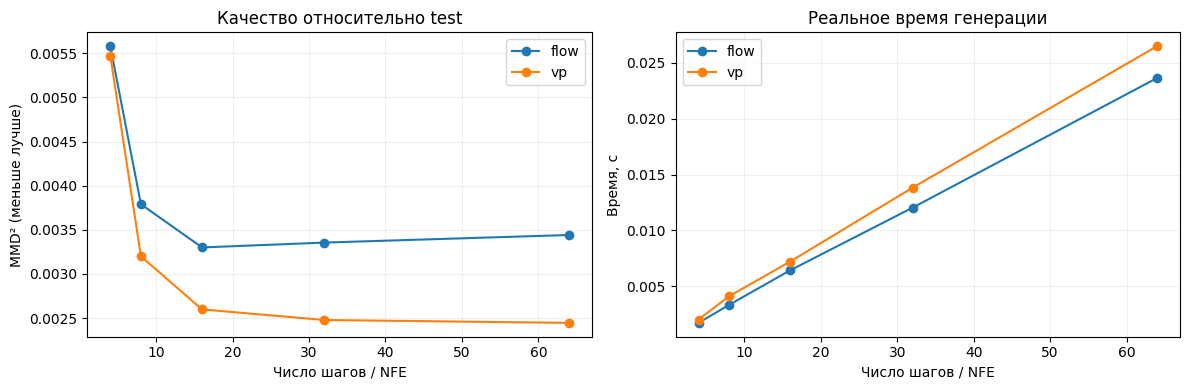

Сводная таблица и график сохранены: /content/artifacts/full_summary.json


In [21]:
# Метрики качества и реальное время сэмплирования: отдельно от несопоставимых train losses.
summary = metrics_df.sort_values(['model', 'steps']).reset_index(drop=True)
display(summary.style.format({'mmd2': '{:.5f}', 'inlier_rate': '{:.3f}',
    'mode_tv': '{:.3f}', 'mean_mode_distance': '{:.3f}', 'sample_seconds': '{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method in ('flow', 'vp'):
    v = summary.loc[summary['model'] == method]
    axes[0].plot(v['steps'], v['mmd2'], '-o', label=method)
    axes[1].plot(v['steps'], v['sample_seconds'], '-o', label=method)
axes[0].set(xlabel='Число шагов / NFE', ylabel='MMD² (меньше лучше)', title='Качество относительно test')
axes[1].set(xlabel='Число шагов / NFE', ylabel='Время, с', title='Реальное время генерации')
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(artifact('steps_comparison.png'), dpi=160); plt.show()

save_json('summary.json', {'config': train_config, 'joint_train_seconds': train_seconds,
    'test_test_mmd2': rbf_mmd2(mmd_test_second, mmd_ref),
    'table': summary.to_dict(orient='records')})
print('Сводная таблица и график сохранены:', artifact('summary.json'))


### Альтернативное coupling

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите поле с угловым pairing на тех же данных и бюджете.

**Результат.** Проверяемое состояние «Альтернативное coupling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите поле с угловым pairing на тех же данных и бюджете» и его результат доступен следующему этапу.

angular  500/3000: MSE=0.1222, 1.1s
angular 1000/3000: MSE=0.1155, 2.2s
angular 1500/3000: MSE=0.1195, 3.3s
angular 2000/3000: MSE=0.0943, 4.4s
angular 2500/3000: MSE=0.0935, 5.7s
angular 3000/3000: MSE=0.0947, 7.1s


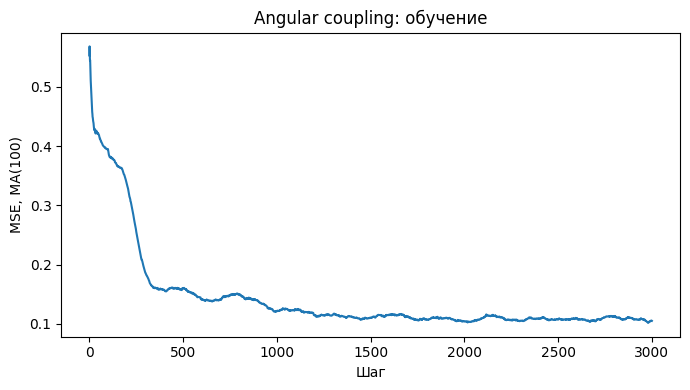

In [22]:
# Контролируемая абляция: меняем ТОЛЬКО pairing x0↔x1, сохранив веса, seed, данные и шаги.
set_seed(SEED)
angular_model = TimeMLP().to(DEVICE)
angular_optimizer = torch.optim.AdamW(angular_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
angular_rng = torch.Generator(device=DEVICE).manual_seed(SEED + 100)
angular_history = []
angular_ckpt = artifact('angular_checkpoint.pt')
angular_config = dict(train_config, pairing='sort_by_polar_angle')
angular_start, angular_previous_seconds = 0, 0.0
if angular_ckpt.exists():
    saved = torch.load(angular_ckpt, map_location=DEVICE, weights_only=False)
    if saved.get('config') == angular_config:
        angular_model.load_state_dict(saved['model'])
        angular_optimizer.load_state_dict(saved['optimizer'])
        angular_rng.set_state(saved['rng_state'])
        angular_history = saved['history']
        angular_start, angular_previous_seconds = saved['step'], saved.get('train_seconds', 0.0)
        print('Возобновление angular flow с шага:', angular_start)

def pair_by_angle(noise, target):
    # Сортировка по углу задает согласованные пары, не меняя сами множества точек.
    i0 = torch.argsort(torch.atan2(noise[:, 1], noise[:, 0]))
    i1 = torch.argsort(torch.atan2(target[:, 1], target[:, 0]))
    paired = torch.empty_like(target)
    paired[i0] = target[i1]
    return paired

def save_angular(step, elapsed):
    torch.save({'config': angular_config, 'step': step, 'model': angular_model.state_dict(),
        'optimizer': angular_optimizer.state_dict(), 'rng_state': angular_rng.get_state(),
        'history': angular_history, 'train_seconds': elapsed}, angular_ckpt)

angular_model.train(); angular_tic = time.perf_counter()
for step in range(angular_start + 1, TRAIN_STEPS + 1):
    idx = torch.randint(N_TRAIN, (BATCH_SIZE,), generator=angular_rng, device=DEVICE)
    x1 = train_points[idx]
    x0 = torch.randn(BATCH_SIZE, 2, generator=angular_rng, device=DEVICE)
    t = torch.rand(BATCH_SIZE, 1, generator=angular_rng, device=DEVICE)
    x1_paired = pair_by_angle(x0, x1)
    xt = (1 - t) * x0 + t * x1_paired
    loss = (angular_model(xt, t) - (x1_paired - x0)).square().mean()
    angular_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    angular_optimizer.step()
    angular_history.append(float(loss.detach()))
    if step == TRAIN_STEPS or step % (1 if FAST_DEV_RUN else 500) == 0:
        elapsed = angular_previous_seconds + time.perf_counter() - angular_tic
        save_angular(step, elapsed)
        print(f'angular {step:4d}/{TRAIN_STEPS}: MSE={angular_history[-1]:.4f}, {elapsed:.1f}s')

angular_seconds = angular_previous_seconds + time.perf_counter() - angular_tic
assert len(angular_history) == TRAIN_STEPS
save_json('angular_history.json', {'config': angular_config,
    'loss': angular_history, 'train_seconds': angular_seconds})
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(angular_history)+1),
        pd.Series(angular_history).rolling(100, min_periods=1).mean())
ax.set(xlabel='Шаг', ylabel='MSE, MA(100)', title='Angular coupling: обучение')
fig.tight_layout(); fig.savefig(artifact('angular_loss.png'), dpi=160); plt.show()


### Поле направлений и траектории

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Изобразите стрелки и траектории; оцените точки из того же исходного шума.

**Результат.** Проверяемое состояние «Поле направлений и траектории» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Изобразите стрелки и траектории; оцените точки из того же исходного шума» и его результат доступен следующему этапу.

,pairing,steps,sample_seconds,mmd2,coverage_8,inlier_rate,mode_tv,mean_mode_distance
0,independent,64,0.02365,0.00344,8,0.94067,0.02856,0.18146
1,angular,64,0.02360,0.00232,8,0.90894,0.02075,0.20754


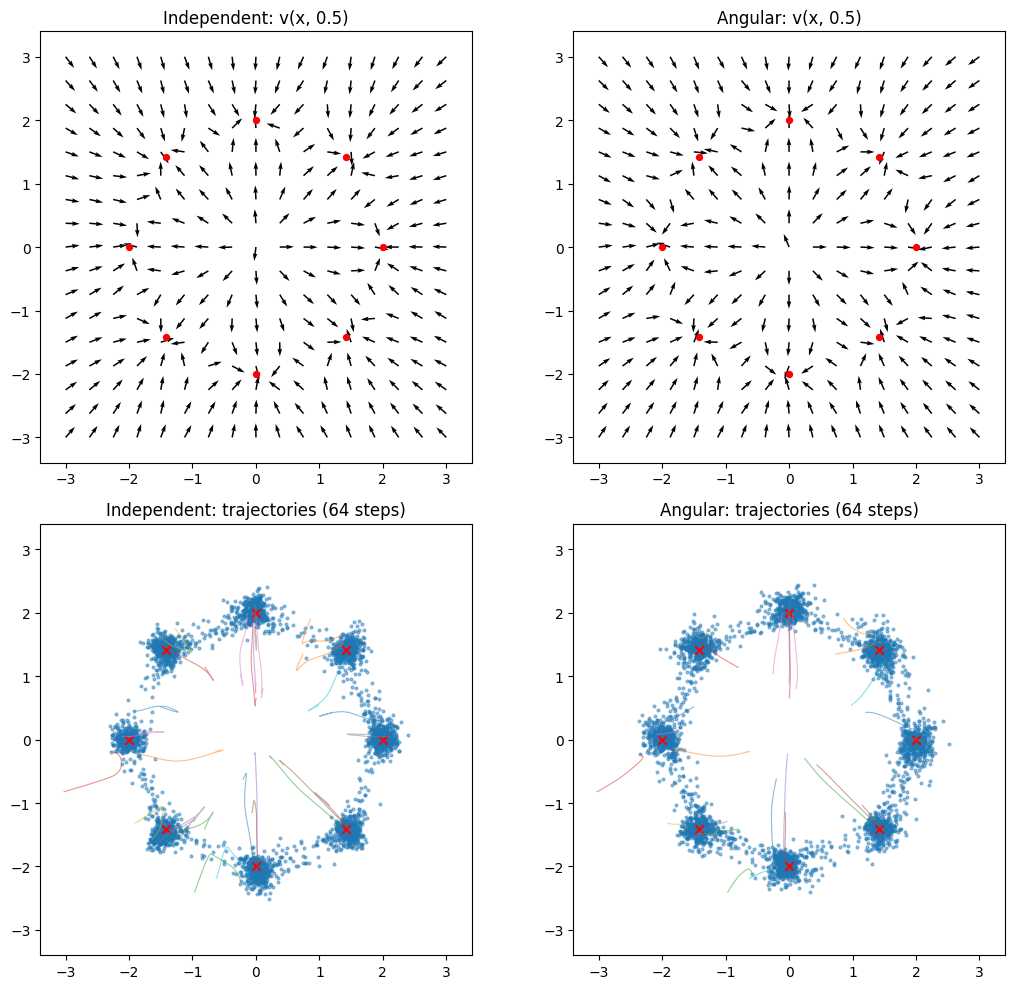

,model,rank,index,x,y,nearest_mode,distance,outlier_vs_test99
0,independent,1,1742,0.7877,-1.9468,6,0.7895,True
1,independent,2,3702,0.8377,-1.9483,7,0.7859,True
2,independent,3,390,0.7744,-1.8504,7,0.7744,True
3,independent,4,1859,-0.7596,1.8675,2,0.7711,True
4,independent,5,2111,0.6737,1.6281,2,0.7695,True
5,angular,1,1009,-1.4690,-0.6065,4,0.8061,True
6,angular,2,1037,2.1975,0.7767,0,0.8014,True
7,angular,3,2803,-0.7880,-1.9222,6,0.7918,True
8,angular,4,759,-1.5609,-0.6428,4,0.7784,True
9,angular,5,3788,1.5925,0.6615,1,0.7735,True


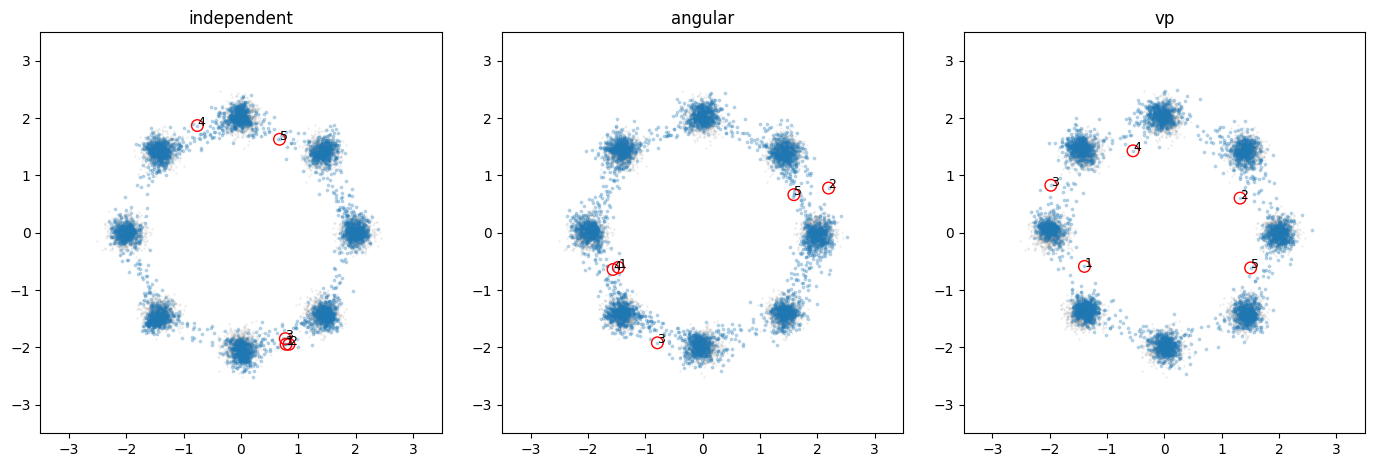

In [23]:
# Одинаковый шум проверяет эффект coupling на итоговых точках; поле — при t=0.5.
VIEW_STEPS = EULER_STEPS[-1]
flow_points, flow_tracks = sample_flow(flow_model, initial_noise, VIEW_STEPS, track=28)
angular_points, angular_tracks = sample_flow(angular_model, initial_noise, VIEW_STEPS, track=28)
angular_np = angular_points.cpu().numpy()
synchronize(); start = time.perf_counter()
_ = sample_flow(angular_model, initial_noise, VIEW_STEPS)
synchronize(); angular_sample_seconds = time.perf_counter() - start

same_step = summary.loc[(summary.model == 'flow') & (summary.steps == VIEW_STEPS)].iloc[0].to_dict()
compare = pd.DataFrame([
    {'pairing': 'independent', 'steps': VIEW_STEPS, 'sample_seconds': float(same_step['sample_seconds']),
     **evaluate_samples(flow_points.cpu().numpy())},
    {'pairing': 'angular', 'steps': VIEW_STEPS, 'sample_seconds': angular_sample_seconds,
     **evaluate_samples(angular_np)}
])
display(compare.round(5))
save_json('coupling_comparison.json', {'rows': compare.to_dict(orient='records'),
    'train_steps_each': TRAIN_STEPS, 'initial_seed': SEED + 202})
torch.save(torch.from_numpy(angular_np), artifact('angular_samples.pt'))

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, net, name in [(axes[0, 0], flow_model, 'Independent'),
                      (axes[0, 1], angular_model, 'Angular')]:
    vals = np.linspace(-3, 3, 17)
    gx, gy = np.meshgrid(vals, vals)
    mesh = torch.from_numpy(np.column_stack([gx.ravel(), gy.ravel()]).astype('float32')).to(DEVICE)
    with torch.inference_mode():
        directions = net(mesh, torch.full((len(mesh), 1), 0.5, device=DEVICE)).cpu().numpy()
    norms = np.maximum(np.linalg.norm(directions, axis=1, keepdims=True), 1e-6)
    uv = directions / norms  # Одинаковая длина показывает именно направления.
    ax.quiver(gx, gy, uv[:, 0].reshape(gx.shape), uv[:, 1].reshape(gy.shape))
    ax.scatter(centers[:, 0], centers[:, 1], c='red', s=18)
    ax.set(title=f'{name}: v(x, 0.5)', xlim=(-3.4,3.4), ylim=(-3.4,3.4), aspect='equal')
for ax, tracks, pts, name in [(axes[1, 0], flow_tracks, flow_points.cpu().numpy(), 'Independent'),
                               (axes[1, 1], angular_tracks, angular_np, 'Angular')]:
    for j in range(tracks.shape[1]):
        ax.plot(tracks[:, j, 0], tracks[:, j, 1], lw=.8, alpha=.5)
    ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=.45)
    ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='x')
    ax.set(title=f'{name}: trajectories ({VIEW_STEPS} steps)', xlim=(-3.4,3.4),
           ylim=(-3.4,3.4), aspect='equal')
fig.tight_layout(); fig.savefig(artifact('vector_fields_trajectories.png'), dpi=160); plt.show()

# Пять наиболее удаленных от мод точек каждой конфигурации для анализа ошибок (фаза 2).
errors, error_sets = [], {'independent': flow_points.cpu().numpy(),
                          'angular': angular_np, 'vp': samples[f'vp_{VIEW_STEPS}']}
for method, pts in error_sets.items():
    d = np.linalg.norm(pts[:, None, :] - centers[None, :, :], axis=2)
    smallest = d.min(axis=1)
    for rank, i in enumerate(np.argsort(smallest)[-5:][::-1], start=1):
        errors.append({'model': method, 'rank': rank, 'index': int(i),
            'x': float(pts[i, 0]), 'y': float(pts[i, 1]),
            'nearest_mode': int(d[i].argmin()), 'distance': float(smallest[i]),
            'outlier_vs_test99': bool(smallest[i] > inlier_threshold)})
errors_df = pd.DataFrame(errors)
display(errors_df.round(4))
save_json('error_cases.json', {'test_99pct_threshold': inlier_threshold,
                               'candidates': errors})
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (name, pts) in zip(axes, error_sets.items()):
    ax.scatter(test_np[:, 0], test_np[:, 1], s=1, alpha=.08, c='gray')
    ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=.25)
    group = errors_df[errors_df.model == name]
    for _, row in group.iterrows():
        ax.scatter(row['x'], row['y'], facecolors='none', edgecolors='red', s=70)
        ax.annotate(str(int(row['rank'])), (row['x'], row['y']), fontsize=9)
    ax.set(title=name, xlim=(-3.5,3.5), ylim=(-3.5,3.5), aspect='equal')
fig.tight_layout(); fig.savefig(artifact('error_cases.png'), dpi=160); plt.show()


### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

,integrator,nfe,mmd2,coverage_8,inlier_rate,mode_tv,mean_mode_distance
0,Euler-32,32,0.00336,8,0.93481,0.02979,0.18316
1,Heun-16,32,0.00351,8,0.94165,0.02856,0.18244


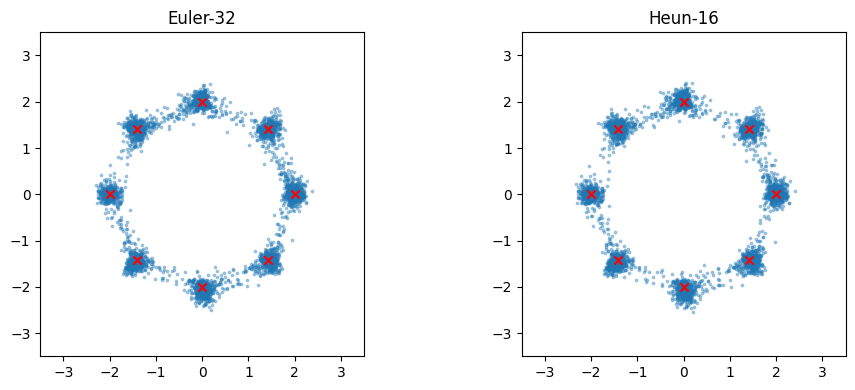

In [24]:
# Бонус: до просмотра чисел гипотеза — Heun(16) улучшит MMD² против Euler(32) при 32 NFE.
# Фиксированы модель, обучающая выборка, seed исходного шума и бюджет вызовов поля.
@torch.inference_mode()
def sample_flow_heun(model, z, steps):
    model.eval()
    x = z.clone()
    dt = 1 / steps
    for i in range(steps):
        t0 = torch.full((len(x), 1), i / steps, dtype=x.dtype, device=x.device)
        t1 = torch.full((len(x), 1), (i+1) / steps, dtype=x.dtype, device=x.device)
        v0 = model(x, t0)
        v1 = model(x + dt*v0, t1)
        x = x + 0.5*dt*(v0 + v1)
    return x

NFE = 32
synchronize(); tic = time.perf_counter()
heun_points = sample_flow_heun(flow_model, initial_noise, NFE // 2)
synchronize(); heun_seconds = time.perf_counter() - tic
baseline_points = sample_flow(flow_model, initial_noise, NFE)[0]
bonus_rows = [
    {'integrator': 'Euler-32', 'nfe': NFE, **evaluate_samples(baseline_points.cpu().numpy())},
    {'integrator': 'Heun-16', 'nfe': NFE, **evaluate_samples(heun_points.cpu().numpy())},
]
bonus_df = pd.DataFrame(bonus_rows)
display(bonus_df.round(5))
save_json('bonus_integrators.json', {'hypothesis': 'Heun-16 даст меньший MMD², чем Euler-32 при 32 NFE',
    'rows': bonus_rows, 'heun_sample_seconds': heun_seconds})
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pts, name in zip(axes, [baseline_points, heun_points], ['Euler-32', 'Heun-16']):
    q = pts.cpu().numpy()
    ax.scatter(q[:, 0], q[:, 1], s=3, alpha=.35)
    ax.scatter(centers[:, 0], centers[:, 1], marker='x', c='red')
    ax.set(title=name, aspect='equal', xlim=(-3.5,3.5), ylim=(-3.5,3.5))
fig.tight_layout(); fig.savefig(artifact('bonus_integrators.png'), dpi=160); plt.show()


### Результаты мини-исследования

**Гипотеза:** Heun-16 обеспечит меньший MMD², чем Euler-32, при одинаковом бюджете 32 NFE.

| Метрика | Euler-32 | Heun-16 |
|---|---:|---:|
| MMD² ↓ | **0.00336** | 0.00351 |
| Inlier ↑ | 93.48% | **94.17%** |
| Mode TV ↓ | 0.02979 | **0.02856** |
| Покрытие мод | 8/8 | 8/8 |

**Результат:** гипотеза по MMD² не подтвердилась. Heun повысил Inlier на 0.69 п.п., но MMD² увеличился на 0.00015.

**Причина:** более точное интегрирование ODE не устраняет ошибки обученного векторного поля.

**Вывод:** при фиксированном NFE преимущество Heun зависит от метрики; существенное улучшение MMD² не установлено.

## Анализ результатов

### 1. Условия эксперимента

- Данные: 8 гауссовских мод, 32768 train / 8192 test, $\sigma=0.14$.
- Обучение: 3000 шагов, batch=512, AdamW, seed=42.
- Генерация: 4096 точек, одинаковый исходный шум.
- Финальный loss: Flow — **1.8107**, VP — **0.4441**. Оба убывают; напрямую несопоставимы.
- Время совместного обучения: **12.75 с**.

### 2. Сравнение генераторов

| Модель | NFE | MMD² ↓ | Inlier ↑ | Время, с |
|---|---:|---:|---:|---:|
| Flow | 4 | 0.00558 | 78.59% | 0.00173 |
| Flow | 8 | 0.00379 | 88.04% | 0.00334 |
| Flow | 16 | 0.00330 | 91.97% | 0.00644 |
| Flow | 32 | 0.00336 | 93.48% | 0.01204 |
| Flow | 64 | 0.00344 | 94.07% | 0.02365 |
| VP | 4 | 0.00547 | 82.57% | 0.00203 |
| VP | 8 | 0.00320 | 88.92% | 0.00411 |
| VP | 16 | 0.00260 | 92.02% | 0.00722 |
| VP | 32 | 0.00248 | 93.51% | 0.01383 |
| VP | 64 | 0.00245 | 93.97% | 0.02650 |

- Обе модели покрывают **8/8 мод** при любом NFE.
- Flow: Inlier вырос с 78.59% до 94.07%.
- VP: MMD² снизился с 0.00547 до 0.00245.
- При 64 NFE VP имеет меньший MMD², Flow — меньшее время генерации.
- Для Flow минимум MMD² достигается при 16 NFE; дальнейшие шаги не улучшают эту метрику.

### 3. Coupling ablation

| Метрика | Independent | Angular |
|---|---:|---:|
| MMD² ↓ | 0.00344 | **0.00232** |
| Inlier ↑ | **94.07%** | 90.89% |
| Mode TV ↓ | 0.02856 | **0.02075** |
| Покрытие | 8/8 | 8/8 |
| Время, с | 0.02365 | 0.02360 |

Angular pairing снизил MMD² на **32.6%**, но ухудшил Inlier на **3.17 п.п.** Геометрия coupling влияет на распределение сэмплов; улучшение одной метрики не гарантирует улучшения остальных.

### 4. Анализ пяти неудачных генераций

Порог Inlier по test: **0.4289**. Все выбранные точки находятся за его пределами.

| Модель | Индекс | Координаты | Расстояние |
|---|---:|---|---:|
| Flow | 1742 | (0.788, −1.947) | 0.790 |
| Flow | 1859 | (−0.760, 1.868) | 0.771 |
| Angular | 1009 | (−1.469, −0.607) | 0.806 |
| Angular | 1037 | (2.198, 0.777) | 0.801 |
| VP | 2344 | (−1.392, −0.589) | 0.825 |

**Предполагаемые причины:**

1. Flow #1742 — точка между нижними модами; неточность поля между кластерами.
2. Flow #1859 — смещение в промежуток верхних мод; усреднение направлений переноса.
3. Angular #1009 — точка между левыми модами; ошибка геометрии learned coupling.
4. Angular #1037 — отклонение от правого кластера; неточность конечного переноса.
5. VP #2344 — точка между нижними левыми модами; ошибка предсказания шума и обратного процесса.

Причины являются гипотезами по геометрии точек, а не доказанными механизмами.

### 5. Ограничения

- Между модами сохраняются ошибочные сэмплы.
- VP использует приближённый старт при $t=0.9$, избегая сингулярности.
- Test-vs-test MMD² = **0.00134**; небольшие различия MMD² требуют проверки на повторных запусках.
- Результаты получены на одной 2D-задаче с одним seed; обобщение на изображения не проверялось.

## Выводы

1. **Rectified Flow реализован корректно:** после 3000 шагов loss = 1.8107; генерация покрывает 8/8 мод.
2. **Увеличение NFE улучшает покрытие:** Flow Inlier вырос с 78.59% до 94.07% при переходе от 4 к 64 шагам.
3. **VP качественнее по MMD² при 64 NFE:** 0.00245 против 0.00344 у Flow, но медленнее (0.02650 против 0.02365 с).
4. **Angular coupling снижает MMD² на 32.6%**, одновременно уменьшая Inlier с 94.07% до 90.89%.
5. **Гипотеза о преимуществе Heun по MMD² не подтвердилась:** 0.00351 против 0.00336 у Euler при 32 NFE.
6. **Основное ограничение:** остаточные точки между модами из-за неточностей обученных полей; увеличение числа шагов не устраняет их полностью.